In [1]:
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer

sentences = [
    "Eu ainda acho que isso é uma péssima ideia",
    "Se você está com medo, pode voltar sozinho",
    "Shh… estamos quase lá",
    "Vocês ouviram isso?",
    "Provavelmente é só o vento",
    "Isso não é vento!",
    "A porta está logo ali",
    "Você tem certeza que é aqui?",
    "Foi o que eu li",
    "Então abre",
    "Devagar",
    "Essa porta vai denunciar a gente",
    "Meu Deus...",
    "O que é aquilo?",
    "Não faz barulho",
    "Ele tem três cabeças",
    "Isso é normal aqui?",
    "Eu realmente espero que não",
    "Ele está acordando",
    "Fecha a porta agora!",
    "Empurra!",
    "Corre!",
    "Não olha pra trás!",
    "Eu disse que era uma péssima ideia",
    "Calma, continua correndo",
    "Vira à esquerda",
    "Espera, alguém está vindo",
    "Se escondam",
    "Fiquem quietos",
    "Ora, ora… o que temos aqui?",
    "Boa noite…",
    "Alunos fora da cama",
    "Nós estávamos apenas…",
    "Silêncio, venham comigo",
    "Estamos encrencados",
    "Eu te disse",
    "Estou profundamente decepcionada",
    "Vocês não fazem ideia do perigo em que estavam",
    "Não há justificativa",
    "Pontos serão retirados",
    "E vocês terão detenção",
    "Mas professora, aquilo estava guardando alguma coisa",
    "Guardando alguma coisa?",
    "Debaixo dele tinha um alçapão",
    "Um alçapão?",
    "Eu vi também",
    "Então não era só um cachorro",
    "O que será que tem lá embaixo?",
    "Não faço ideia, mas deve ser importante",
    "Ninguém colocaria uma criatura daquelas por acaso",
    "Você acha que é algo proibido?",
    "Ou algo muito valioso",
    "Se for, alguém está tentando proteger",
    "Ou esconder",
    "A gente não devia estar falando disso",
    "Mas agora eu não consigo parar de pensar",
    "Nem eu",
    "Isso explica muita coisa",
    "Ou complica ainda mais",
    "De qualquer forma, precisamos tomar cuidado",
    "E ficar longe daquele corredor",
    "Pelo menos por enquanto",
    "Concordo",
    "Mas eu ainda quero descobrir o que tem lá"
]


model_name = "bert-base-multilingual-cased"  

tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
model = AutoModel.from_pretrained(model_name, output_attentions=True)
model.eval()

# junta as frases em um texto único
sep = " [SEP] "
text = sep.join(sentences)

# offsets para mapear tokens -> frases
enc = tokenizer(
    text,
    return_tensors="pt",
    return_offsets_mapping=True,
    truncation=True,
    max_length=512
)

offsets = enc.pop("offset_mapping")[0].numpy()

with torch.no_grad():
    out = model(**enc)

# attention: lista de camadas, cada uma com shape
# (batch, heads, seq_len, seq_len)
attentions = out.attentions

# média sobre camadas e heads
A = torch.stack(attentions).mean(dim=0)[0].mean(dim=0).cpu().numpy()

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sofia\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as

In [2]:

spans = []
start = 0
for s in sentences:
    end = start + len(s)
    spans.append((start, end))
    start = end + len(sep)

def token_to_sentence_idx(char_start, char_end):
    for i, (s0, s1) in enumerate(spans):
        if char_start >= s0 and char_end <= s1:
            return i
    return None

token_sentence = []
for i, (cs, ce) in enumerate(offsets):
    if cs == ce == 0:  # tokens especiais
        token_sentence.append(None)
    else:
        token_sentence.append(token_to_sentence_idx(cs, ce))

In [3]:
spans = []
start = 0
for s in sentences:
    end = start + len(s)
    spans.append((start, end))
    start = end + len(sep)

def token_to_sentence_idx(char_start, char_end):
    for i, (s0, s1) in enumerate(spans):
        if char_start >= s0 and char_end <= s1:
            return i
    return None

token_sentence = []
for i, (cs, ce) in enumerate(offsets):
    if cs == ce == 0:  # tokens especiais
        token_sentence.append(None)
    else:
        token_sentence.append(token_to_sentence_idx(cs, ce))

In [4]:
A = torch.stack(attentions).mean(dim=0)[0].mean(dim=0).cpu().numpy()
n = len(sentences)
M = np.zeros((n, n))
C = np.zeros((n, n))

for ti, si in enumerate(token_sentence):
    if si is None:
        continue
    for tj, sj in enumerate(token_sentence):
        if sj is None:
            continue
        M[si, sj] += A[ti, tj]
        C[si, sj] += 1


M = np.divide(M, C, out=np.zeros_like(M), where=C > 0)

In [5]:
boundary_score = []

for i in range(n - 1):
    cross = 0.5 * (M[i, i+1] + M[i+1, i])   # ligação entre as duas frases
    score = 1 - cross
    boundary_score.append(score)

boundary_score = np.array(boundary_score)

top_boundaries = np.argsort(boundary_score)[::-1][:5]

print("Maiores mudanças de contexto:")
for i in top_boundaries:
    print(f"\nEntre {i} e {i+1} | score = {boundary_score[i]:.4f}")
    print("A:", sentences[i])
    print("B:", sentences[i+1])

Maiores mudanças de contexto:

Entre 48 e 49 | score = 0.9989
A: Não faço ideia, mas deve ser importante
B: Ninguém colocaria uma criatura daquelas por acaso

Entre 36 e 37 | score = 0.9988
A: Estou profundamente decepcionada
B: Vocês não fazem ideia do perigo em que estavam

Entre 42 e 43 | score = 0.9988
A: Guardando alguma coisa?
B: Debaixo dele tinha um alçapão

Entre 49 e 50 | score = 0.9988
A: Ninguém colocaria uma criatura daquelas por acaso
B: Você acha que é algo proibido?

Entre 46 e 47 | score = 0.9988
A: Então não era só um cachorro
B: O que será que tem lá embaixo?


In [6]:
influence = np.zeros(n)

for i in range(n):
    future_mass = M[i+1:, i].sum() if i + 1 < n else 0
    outgoing_mass = M[i, i+1:].sum() if i + 1 < n else 0
    influence[i] = future_mass + outgoing_mass

top_influential = np.argsort(influence)[::-1][:5]

print("Falas mais influentes:")
for i in top_influential:
    print(f"\nÍndice {i} | influence = {influence[i]:.4f}")
    print(sentences[i])

Falas mais influentes:

Índice 5 | influence = 0.1202
Isso não é vento!

Índice 0 | influence = 0.1147
Eu ainda acho que isso é uma péssima ideia

Índice 2 | influence = 0.1091
Shh… estamos quase lá

Índice 1 | influence = 0.1078
Se você está com medo, pode voltar sozinho

Índice 3 | influence = 0.1067
Vocês ouviram isso?


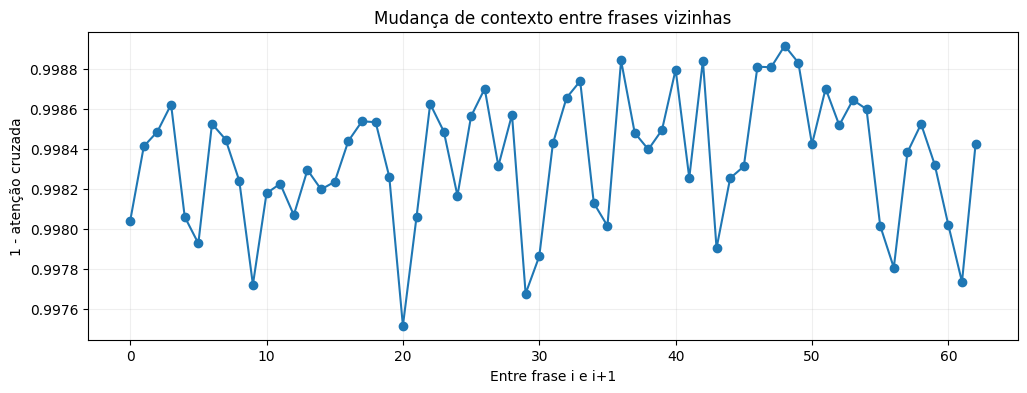

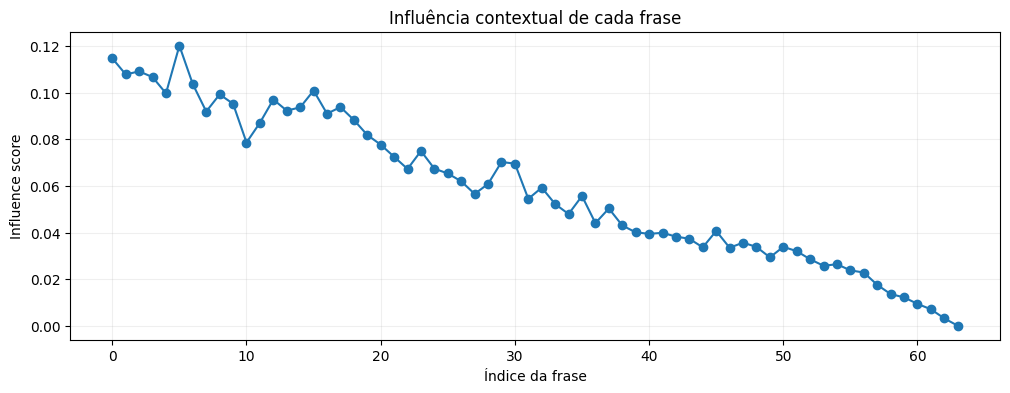

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(boundary_score, marker="o")
plt.title("Mudança de contexto entre frases vizinhas")
plt.xlabel("Entre frase i e i+1")
plt.ylabel("1 - atenção cruzada")
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(influence, marker="o")
plt.title("Influência contextual de cada frase")
plt.xlabel("Índice da frase")
plt.ylabel("Influence score")
plt.grid(alpha=0.2)
plt.show()